# 09 — External validation (E4)

Apply the frozen three-day models (flat RF + Set A from notebook 07 and the hierarchical cascade from notebook 08) to two external participants, Laura and Monika. Both contribute one day each, so only E4 (uncalibrated) is feasible. E5 (day-1 calibration to day-2 test) is not possible with the available external data.

**No retraining happens in this notebook.** The frozen pickles are loaded and used as-is. The point of E4 is to test the out-of-distribution performance of artifacts already produced.

**Preprocessing equivalence.** External raw data is preprocessed using `src/preprocessing.preprocess_session`, which mirrors notebook 02's policy: 50 Hz resampling, 10-second edge trimming, three-tier gap policy. The first section of this notebook is a smoke test that runs the preprocessing on one internal session and compares the output against the existing interim file. If the smoke test fails, do not proceed with external prediction.

**Outputs.**
- `data/interim_external/<participant>_<mode>_day1.csv`: preprocessed external sessions.
- `data/processed_external/features_external_*.csv`: four feature CSVs for externals.
- `reports/results/external_e4_flat_rf.csv`: per-window predictions from flat RF.
- `reports/results/external_e4_cascade.csv`: per-window predictions from cascade.
- `reports/results/external_e4_summary.csv`: macro-F1 and per-class F1 for both models.
- `reports/figures/cm_external_*.png`: confusion matrices.

## 1. Setup

In [1]:
import sys
import pickle
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    f1_score, confusion_matrix, classification_report,
)

warnings.filterwarnings('ignore')

PROJECT_ROOT = Path('..').resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import features as F
from src.preprocessing import preprocess_session, discover_external_sessions
from src.data_loading import build_session_index

# Paths
RAW_EXT_DIR        = PROJECT_ROOT / 'data' / 'raw' / 'external'
INTERIM_EXT_DIR    = PROJECT_ROOT / 'data' / 'interim_external'
PROCESSED_EXT_DIR  = PROJECT_ROOT / 'data' / 'processed_external'
INTERIM_INT_DIR    = PROJECT_ROOT / 'data' / 'interim'
PROCESSED_INT_DIR  = PROJECT_ROOT / 'data' / 'processed'
FEATURES_DIR       = PROJECT_ROOT / 'reports' / 'features'
RESULTS_DIR        = PROJECT_ROOT / 'reports' / 'results'
FIGURES_DIR        = PROJECT_ROOT / 'reports' / 'figures'

INTERIM_EXT_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_EXT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Internal baselines from notebook 07 and 08 (for comparison)
INTERNAL_LOSO_FLAT_RF = 0.568
INTERNAL_LOSO_CASCADE = 0.572

## 2. Discover external sessions

Scan `data/raw/external/` for participant folders and session folders. Notebook expects the structure:

```
data/raw/external/
├── laura/
│   ├── laura_walking_day1/
│   ├── laura_cycling_day1/
│   └── ... (one folder per mode)
└── monika/
    └── ...
```

The discovery function is tolerant of two layout variations (see `discover_external_sessions` docstring). If sessions are not discovered with the expected naming, the cell below shows what was found so you can fix the structure before running preprocessing.

In [2]:
external_sessions = discover_external_sessions(RAW_EXT_DIR)

if not external_sessions:
    print(f'No external sessions found in {RAW_EXT_DIR}.')
    print(f'Expected structure: data/raw/external/<participant>/<participant>_<mode>_day1/')
else:
    print(f'Found {len(external_sessions)} external sessions:')
    for s in external_sessions:
        valid_mode = s['mode'] in F.MODES
        marker = 'OK' if valid_mode else 'WARN unknown mode'
        print(f"  [{marker}] {s['session_id']:30s} -> {s['path'].name}")

# Group by participant and mode coverage
if external_sessions:
    df_sessions = pd.DataFrame(external_sessions)
    print()
    print('Mode coverage per participant:')
    pivot = df_sessions.pivot_table(
        index='participant', columns='mode', values='session_id',
        aggfunc='count', fill_value=0
    )
    print(pivot)

Found 18 external sessions:
  [OK] laura_bus_day1                 -> bus_day1
  [OK] laura_cycling_day1             -> cycling_day1
  [OK] laura_metro_day1               -> metro_day1
  [OK] laura_stationary_day1          -> stationary_day1
  [OK] laura_tram_day1                -> tram_day1
  [OK] laura_walking_day1             -> walking_day1
  [OK] maria_bus_day1                 -> bus_day1
  [OK] maria_cycling_day1             -> cycling_day1
  [OK] maria_metro_day1               -> metro_day1
  [OK] maria_stationary_day1          -> stationary_day1
  [OK] maria_tram_day1                -> tram_day1
  [OK] maria_walking_day1             -> walking_day1
  [OK] monika_bus_day1                -> bus_day1
  [OK] monika_cycling_day1            -> cycling_day1
  [OK] monika_metro_day1              -> metro_day1
  [OK] monika_stationary_day1         -> stationary_day1
  [OK] monika_tram_day1               -> tram_day1
  [OK] monika_walking_day1            -> walking_day1

Mode coverage per

## 3. Smoke test: preprocessing equivalence

Before preprocessing externals, verify that `preprocess_session` produces the same output as notebook 02 did on internal data. This catches any mismatch in policy (sampling rate, trim, gap thresholds) before it can contaminate the external results.

The test picks one internal session, finds its raw folder (we assume `data/raw/<participant>/<session_id>/`), preprocesses it with `preprocess_session`, and compares to the existing `data/interim/<session_id>.csv`.

**If the smoke test fails:** the preprocessing function and notebook 02 differ in some way. Options:
1. Adjust the constants in `src/preprocessing.py` to match notebook 02 (most likely fix).
2. Use notebook 02 directly to preprocess externals: run it with `RAW_DIR=data/raw/external` and `INTERIM_DIR=data/interim_external`. Then skip the next section and go straight to featurization.

Either path is fine. The point is to know whether the preprocessing matches before applying frozen models.

In [3]:
RAW_INT_DIR = PROJECT_ROOT / 'data' / 'raw'

# Try to find a sample internal session for the smoke test
internal_interim_files = sorted(INTERIM_INT_DIR.glob('*_day*.csv'))
if not internal_interim_files:
    print('No internal interim files found; skipping smoke test.')
    smoke_test_done = False
else:
    smoke_test_done = False
    sample_interim = internal_interim_files[0]
    session_id = sample_interim.stem  # e.g. 'babis_walking_day1'
    print(f'Smoke test on session: {session_id}')

    # Find the matching raw folder. Try a few common layouts.
    candidates = [
        RAW_INT_DIR / session_id.split('_')[0] / session_id,
        RAW_INT_DIR / session_id,
        RAW_INT_DIR / session_id.split('_')[0] / '_'.join(session_id.split('_')[1:]),
    ]
    raw_dir = next((p for p in candidates if p.exists() and p.is_dir()), None)

    if raw_dir is None:
        print(f'Could not locate raw folder for {session_id}. Tried:')
        for c in candidates:
            print(f'  {c}')
        print('Smoke test skipped. Verify preprocessing manually before proceeding.')
    else:
        print(f'Found raw folder: {raw_dir}')
        smoke_out = INTERIM_EXT_DIR / f'_smoke_{session_id}.csv'
        try:
            info = preprocess_session(raw_dir, smoke_out)
            print(f'  Preprocessing OK: {info}')

            ref = pd.read_csv(sample_interim)
            new = pd.read_csv(smoke_out)

            print(f'  Reference columns: {list(ref.columns)}')
            print(f'  New columns:       {list(new.columns)}')
            print(f'  Reference rows:    {len(ref)}')
            print(f'  New rows:          {len(new)}')

            shared = sorted(set(ref.columns) & set(new.columns) - {'t'})
            print(f'  Shared data columns: {shared}')

            n_compare = min(len(ref), len(new))
            mismatches = []
            for col in shared:
                if col in ('flagged_sample', 'bad_sample'):
                    continue  # gap masks may differ slightly; not critical
                ref_vals = ref[col].values[:n_compare]
                new_vals = new[col].values[:n_compare]
                rel_diff = np.abs(ref_vals - new_vals).mean() / (np.abs(ref_vals).mean() + 1e-9)
                if rel_diff > 0.01:
                    mismatches.append((col, rel_diff))
                else:
                    print(f'  [OK] {col}: mean rel diff = {rel_diff:.4f}')

            if mismatches:
                print(f'  WARNING: {len(mismatches)} columns differ by >1% from reference:')
                for col, diff in mismatches:
                    print(f'    {col}: {diff:.4f}')
                print('  Consider using notebook 02 directly for externals (see section 3 markdown).')
            else:
                print('  [PASS] Smoke test: preprocessing matches notebook 02 within tolerance.')
                smoke_test_done = True

            smoke_out.unlink()  # clean up
        except Exception as exc:
            print(f'  Smoke test FAILED: {exc}')
            print('  Use notebook 02 directly for externals; see section 3 markdown.')

Smoke test on session: athina_bus_day1
Found raw folder: C:\Projects\this project-transport-mode\data\raw\athina\bus_day1
  Preprocessing OK: {'n_samples': 34672, 'duration_s': 693.435257888, 'n_bad': 0, 'n_flagged': 0, 'sensors_used': ['accelerometer', 'gyroscope', 'linear_acc'], 'fs': 50.0}
  Reference columns: ['t', 'ax', 'ay', 'az', 'lin_ax', 'lin_ay', 'lin_az', 'gx', 'gy', 'gz', 'pressure', 'bad_sample', 'flagged_sample']
  New columns:       ['t', 'lin_ax', 'lin_ay', 'lin_az', 'gx', 'gy', 'gz', 'acc_x', 'acc_y', 'acc_z', 'flagged_sample', 'bad_sample']
  Reference rows:    34672
  New rows:          34672
  Shared data columns: ['bad_sample', 'flagged_sample', 'gx', 'gy', 'gz', 'lin_ax', 'lin_ay', 'lin_az']
  [OK] gx: mean rel diff = 0.0001
  [OK] gy: mean rel diff = 0.0000
  [OK] gz: mean rel diff = 0.0001
  [OK] lin_ax: mean rel diff = 0.0016
  [OK] lin_ay: mean rel diff = 0.0015
  [OK] lin_az: mean rel diff = 0.0015
  [PASS] Smoke test: preprocessing matches notebook 02 within

## 4. Preprocess external sessions

Run `preprocess_session` on every external session folder. Outputs go to `data/interim_external/<participant>_<mode>_day1.csv`. If a session fails (missing required sensors, too short, file format issues), log it and continue.

If you decided in section 3 to use notebook 02 directly instead, skip this section. The notebook will pick up from `data/interim_external/` in section 5 either way.

In [4]:
preprocess_results = []
for sess in external_sessions:
    if sess['mode'] not in F.MODES:
        print(f"SKIP {sess['session_id']}: mode '{sess['mode']}' not in {F.MODES}")
        continue
    out_path = INTERIM_EXT_DIR / f"{sess['session_id']}.csv"
    try:
        info = preprocess_session(sess['path'], out_path)
        preprocess_results.append({
            'session_id':  sess['session_id'],
            'participant': sess['participant'],
            'mode':        sess['mode'],
            **info,
        })
        print(f"OK   {sess['session_id']:30s} {info['n_samples']:>6d} samples, "
              f"{info['duration_s']:6.1f}s, sensors={info['sensors_used']}")
    except Exception as exc:
        print(f"FAIL {sess['session_id']:30s} {exc}")

if preprocess_results:
    summary_df = pd.DataFrame(preprocess_results)
    print(f'\nProcessed {len(preprocess_results)} sessions successfully')
    print('Per-participant totals:')
    print(summary_df.groupby('participant')['n_samples'].agg(['count', 'sum']).rename(
        columns={'count': 'sessions', 'sum': 'total_samples'}))

OK   laura_bus_day1                  34523 samples,  690.4s, sensors=['accelerometer', 'barometer', 'gyroscope', 'linear_acc']
OK   laura_cycling_day1              32462 samples,  649.2s, sensors=['accelerometer', 'barometer', 'gyroscope', 'linear_acc']
OK   laura_metro_day1                33317 samples,  666.3s, sensors=['accelerometer', 'barometer', 'gyroscope', 'linear_acc']
OK   laura_stationary_day1           34434 samples,  688.7s, sensors=['accelerometer', 'barometer', 'gyroscope', 'linear_acc']
OK   laura_tram_day1                 33791 samples,  675.8s, sensors=['accelerometer', 'barometer', 'gyroscope', 'linear_acc']
OK   laura_walking_day1              34379 samples,  687.6s, sensors=['accelerometer', 'barometer', 'gyroscope', 'linear_acc']
OK   maria_bus_day1                  28512 samples,  570.2s, sensors=['accelerometer', 'gyroscope', 'linear_acc']
OK   maria_cycling_day1              29969 samples,  599.4s, sensors=['accelerometer', 'gyroscope', 'linear_acc']
OK   maria

## 5. Featurize external sessions

Apply the same feature extraction used in notebooks 04, 04b, 04c to the external interim files. Produces four CSVs in `data/processed_external/` matching the structure of `data/processed/`:
- `features_external_no_baro.csv`: 129 standard features
- `features_external_no_baro_normalized.csv`: per-session normalized variants (prefix `norm_`)
- `features_external_no_baro_extended.csv`: standard plus 12 event features (prefix `event_`)
- `features_external_no_baro_multiscale.csv`: 19 multi-scale features (prefix `ms_`)

In [5]:
# Build session index from external interim
ext_session_index = build_session_index(INTERIM_EXT_DIR)
ext_session_index = [s for s in ext_session_index if s['mode'] in F.MODES]
print(f'External sessions ready for featurization: {len(ext_session_index)}')

# Standard features
std_rows = []
for sess in ext_session_index:
    meta = {
        'session_id':  sess['session_id'],
        'participant': sess['participant'],
        'mode':        sess['mode'],
        'mode_id':     F.MODE_TO_ID[sess['mode']],
        'day':         sess['day'],
    }
    feat_rows, _ = F.featurise_session(Path(sess['path']), meta)
    std_rows.extend(feat_rows)
std_df = pd.DataFrame(std_rows)

meta_cols = ['session_id', 'participant', 'mode', 'mode_id', 'day',
             'window_index', 'window_start_s', 'window_end_s', 'flagged_frac']
feat_cols = [c for c in std_df.columns if c not in meta_cols]
std_df[feat_cols] = std_df[feat_cols].fillna(0.0).replace([np.inf, -np.inf], 0.0)
std_out = PROCESSED_EXT_DIR / 'features_external_no_baro.csv'
std_df.to_csv(std_out, index=False)
print(f'Standard: {len(std_df)} rows x {len(std_df.columns)} cols -> {std_out.name}')

External sessions ready for featurization: 18
Standard: 5274 rows x 150 cols -> features_external_no_baro.csv


In [6]:
# Extended features (standard + event)
ext_rows = []
for sess in ext_session_index:
    meta = {
        'session_id':  sess['session_id'],
        'participant': sess['participant'],
        'mode':        sess['mode'],
        'mode_id':     F.MODE_TO_ID[sess['mode']],
        'day':         sess['day'],
    }
    feat_rows, _ = F.featurise_session(
        Path(sess['path']), meta, include_event_features=True
    )
    ext_rows.extend(feat_rows)
ext_df = pd.DataFrame(ext_rows)
feat_cols = [c for c in ext_df.columns if c not in meta_cols]
ext_df[feat_cols] = ext_df[feat_cols].fillna(0.0).replace([np.inf, -np.inf], 0.0)
ext_df.to_csv(PROCESSED_EXT_DIR / 'features_external_no_baro_extended.csv', index=False)
print(f'Extended: {len(ext_df)} rows x {len(ext_df.columns)} cols')

Extended: 5274 rows x 162 cols


In [7]:
# Normalized features (per-session RMS normalized)
norm_rows = []
for sess in ext_session_index:
    meta = {
        'session_id':  sess['session_id'],
        'participant': sess['participant'],
        'mode':        sess['mode'],
        'mode_id':     F.MODE_TO_ID[sess['mode']],
        'day':         sess['day'],
    }
    feat_rows, _ = F.featurise_session(
        Path(sess['path']), meta, apply_session_normalization=True
    )
    norm_rows.extend(feat_rows)
norm_df = pd.DataFrame(norm_rows)
feat_cols = [c for c in norm_df.columns if c not in meta_cols]
norm_df[feat_cols] = norm_df[feat_cols].fillna(0.0).replace([np.inf, -np.inf], 0.0)
rename = {c: f'norm_{c}' for c in feat_cols}
norm_df = norm_df.rename(columns=rename)
norm_df.to_csv(PROCESSED_EXT_DIR / 'features_external_no_baro_normalized.csv', index=False)
print(f'Normalized: {len(norm_df)} rows x {len(norm_df.columns)} cols')

Normalized: 5274 rows x 150 cols


In [8]:
# Multi-scale features (15-second context windows)
ms_rows = []
for sess in ext_session_index:
    df_sess = pd.read_csv(sess['path']).reset_index(drop=True)
    has_bad = 'bad_sample' in df_sess.columns
    for w_idx, (s, e) in enumerate(F.iterate_windows(len(df_sess))):
        if has_bad and bool(df_sess.iloc[s:e]['bad_sample'].any()):
            continue
        try:
            ms_feats = F.compute_multiscale_features(df_sess, s, e)
        except Exception:
            continue
        ms_rows.append({
            'session_id':  sess['session_id'],
            'participant': sess['participant'],
            'mode':        sess['mode'],
            'mode_id':     F.MODE_TO_ID[sess['mode']],
            'day':         sess['day'],
            'window_index': w_idx,
            'window_start_s': float(s / F.SAMPLING_RATE),
            'window_end_s':   float(e / F.SAMPLING_RATE),
            'flagged_frac':   0.0,
            **ms_feats,
        })
ms_df = pd.DataFrame(ms_rows)
ms_feat_cols = [c for c in ms_df.columns if c not in meta_cols]
ms_df[ms_feat_cols] = ms_df[ms_feat_cols].fillna(0.0).replace([np.inf, -np.inf], 0.0)
ms_df.to_csv(PROCESSED_EXT_DIR / 'features_external_no_baro_multiscale.csv', index=False)
print(f'Multi-scale: {len(ms_df)} rows x {len(ms_df.columns)} cols')

Multi-scale: 5274 rows x 28 cols


## 6. Load frozen models

Load the artifacts saved by notebooks 07 (flat RF) and 08 (hierarchical cascade). Neither model is retrained on external data.

In [9]:
with open(RESULTS_DIR / 'rf_three_days_best_pipeline.pkl', 'rb') as f:
    rf_artifact = pickle.load(f)
print(f'Flat RF artifact: {list(rf_artifact.keys())}')

with open(RESULTS_DIR / 'hierarchical_cascade.pkl', 'rb') as f:
    cascade_artifact = pickle.load(f)
print(f'Cascade artifact: {list(cascade_artifact.keys())}')

Flat RF artifact: ['model', 'feature_set', 'feature_names', 'mode_to_id', 'best_params', 'loso_macro_f1', 'loso_macro_f1_std', 'two_day_baseline']
Cascade artifact: ['models', 'level_features', 'rf_kwargs', 'mode_to_id', 'l3b_modes', 'l3b_map', 'active_modes', 'vehicle_modes', 'cascade_e2_mean', 'cascade_e2_std', 'flat_baseline']


## 7. Apply flat RF + Set A to externals

Predict on every external window using the frozen flat RF model. Report overall macro-F1, per-participant macro-F1, and per-class F1.

In [10]:
# Reload the standard feature CSV (the flat RF uses Set A which lives in this file)
ext_std = pd.read_csv(PROCESSED_EXT_DIR / 'features_external_no_baro.csv')

# Identify the feature columns the RF was trained on
rf_features = rf_artifact.get('feature_names') or rf_artifact.get('features')
if rf_features is None:
    # Fallback: pull from the inventory file as Set A = time_domain_basic + slope
    inv = pd.read_csv(FEATURES_DIR / 'feature_inventory.csv')
    rf_features = inv.loc[inv['family'].isin(['time_domain_basic', 'slope']), 'feature'].tolist()
    rf_features = [f for f in rf_features if f in ext_std.columns]
print(f'RF features: {len(rf_features)}')

# Verify all expected features exist in external data
missing = [c for c in rf_features if c not in ext_std.columns]
if missing:
    print(f'MISSING in external data: {missing[:10]}')
    raise ValueError('External features missing required columns')

X_ext = ext_std[rf_features].values
y_ext_true = ext_std['mode_id'].values

# Get the RF model
rf_model = rf_artifact.get('model') or rf_artifact.get('pipeline') or rf_artifact
y_ext_pred_rf = rf_model.predict(X_ext)

rf_e4 = f1_score(y_ext_true, y_ext_pred_rf, average='macro')
print(f'\nFlat RF + Set A on externals (E4): macro-F1 = {rf_e4:.3f}')
print(f'Internal LOSO baseline:                       {INTERNAL_LOSO_FLAT_RF:.3f}')
print(f'Delta:                                         {rf_e4 - INTERNAL_LOSO_FLAT_RF:+.3f}')

# Per-participant breakdown
ext_std['pred_rf'] = y_ext_pred_rf
print('\nPer-participant macro-F1:')
for p, sub in ext_std.groupby('participant'):
    p_f1 = f1_score(sub['mode_id'], sub['pred_rf'], average='macro')
    print(f'  {p:10s}: {p_f1:.3f} ({len(sub)} windows)')

RF features: 80

Flat RF + Set A on externals (E4): macro-F1 = 0.602
Internal LOSO baseline:                       0.568
Delta:                                         +0.034

Per-participant macro-F1:
  laura     : 0.767 (1615 windows)
  maria     : 0.462 (1480 windows)
  monika    : 0.552 (2179 windows)


## 8. Apply hierarchical cascade to externals

Predict on every external window using the cascade. The cascade prediction logic from notebook 08 is reimplemented here for clarity.

In [11]:
# Merge the three external feature CSVs for cascade
ext_norm = pd.read_csv(PROCESSED_EXT_DIR / 'features_external_no_baro_normalized.csv')
ext_ext  = pd.read_csv(PROCESSED_EXT_DIR / 'features_external_no_baro_extended.csv')
ext_ms   = pd.read_csv(PROCESSED_EXT_DIR / 'features_external_no_baro_multiscale.csv')

join_keys = ['session_id', 'window_index']
norm_cols = [c for c in ext_norm.columns if c.startswith('norm_')]
event_cols = [c for c in ext_ext.columns if c.startswith('event_')]
ms_cols = [c for c in ext_ms.columns if c.startswith('ms_')]

ext_merged = ext_std.drop(columns=['pred_rf'])
ext_merged = ext_merged.merge(ext_norm[join_keys + norm_cols], on=join_keys, how='inner')
ext_merged = ext_merged.merge(ext_ext[join_keys + event_cols], on=join_keys, how='inner')
ext_merged = ext_merged.merge(ext_ms[join_keys + ms_cols], on=join_keys, how='inner')
print(f'Merged external: {len(ext_merged)} rows x {len(ext_merged.columns)} cols')

Merged external: 5274 rows x 322 cols


In [12]:
# Cascade prediction function (copy of notebook 08's predict_cascade)
def predict_cascade_ext(models, level_features, test_df, l3b_modes):
    n = len(test_df)
    final = np.full(n, -1, dtype=int)
    test_df = test_df.reset_index(drop=True)

    l1_pred = models['L1'].predict(test_df[level_features['L1']].values)

    # Active -> L2A (walking vs cycling)
    active_mask = (l1_pred == 1)
    if active_mask.any():
        X = test_df.loc[active_mask, level_features['L2A']].values
        l2a_pred = models['L2A'].predict(X)
        active_idx = np.where(active_mask)[0]
        final[active_idx[l2a_pred == 0]] = F.MODE_TO_ID['walking']
        final[active_idx[l2a_pred == 1]] = F.MODE_TO_ID['cycling']

    # Passive -> L2B (stationary vs vehicle)
    passive_mask = (l1_pred == 0)
    if passive_mask.any():
        X = test_df.loc[passive_mask, level_features['L2B']].values
        l2b_pred = models['L2B'].predict(X)
        passive_idx = np.where(passive_mask)[0]
        stat_local = (l2b_pred == 0)
        final[passive_idx[stat_local]] = F.MODE_TO_ID['stationary']
        veh_local = (l2b_pred == 1)
        if veh_local.any():
            veh_idx = passive_idx[veh_local]
            X = test_df.iloc[veh_idx][level_features['L3B']].values
            l3b_pred = models['L3B'].predict(X)
            for cls, mode in enumerate(l3b_modes):
                final[veh_idx[l3b_pred == cls]] = F.MODE_TO_ID[mode]
    return final

cascade_models = cascade_artifact['models']
level_features = cascade_artifact['level_features']
l3b_modes = cascade_artifact['l3b_modes']

# Verify all features are present
for level, cols in level_features.items():
    missing = [c for c in cols if c not in ext_merged.columns]
    if missing:
        print(f'{level} missing: {missing[:5]}')
        raise ValueError(f'External features missing for cascade level {level}')

y_ext_pred_cascade = predict_cascade_ext(cascade_models, level_features, ext_merged, l3b_modes)
y_ext_true_cascade = ext_merged['mode_id'].values

cascade_e4 = f1_score(y_ext_true_cascade, y_ext_pred_cascade, average='macro')
print(f'Hierarchical cascade on externals (E4): macro-F1 = {cascade_e4:.3f}')
print(f'Internal LOSO baseline:                            {INTERNAL_LOSO_CASCADE:.3f}')
print(f'Delta:                                              {cascade_e4 - INTERNAL_LOSO_CASCADE:+.3f}')

ext_merged['pred_cascade'] = y_ext_pred_cascade
print('\nPer-participant macro-F1:')
for p, sub in ext_merged.groupby('participant'):
    p_f1 = f1_score(sub['mode_id'], sub['pred_cascade'], average='macro')
    print(f'  {p:10s}: {p_f1:.3f} ({len(sub)} windows)')

Hierarchical cascade on externals (E4): macro-F1 = 0.594
Internal LOSO baseline:                            0.572
Delta:                                              +0.022

Per-participant macro-F1:
  laura     : 0.755 (1615 windows)
  maria     : 0.467 (1480 windows)
  monika    : 0.516 (2179 windows)


## 9. Confusion matrices

Six-class confusion matrices on externals: one for the flat RF, one for the cascade. Directly comparable to the internal LOSO matrices from notebooks 07 and 08.

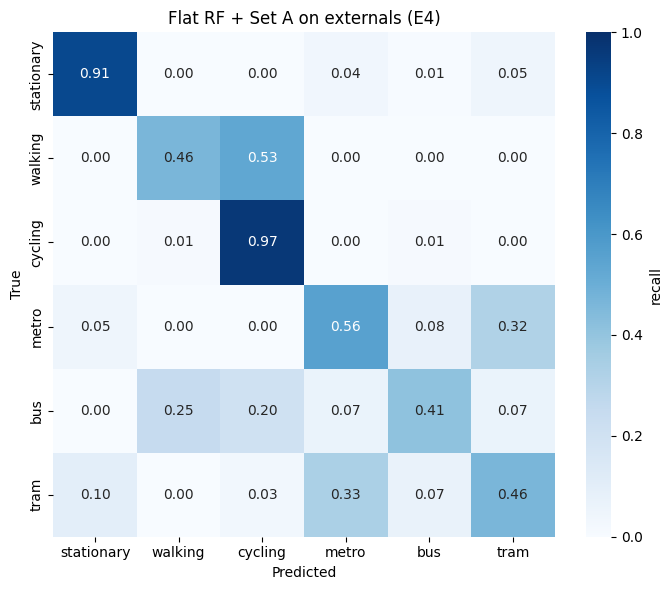

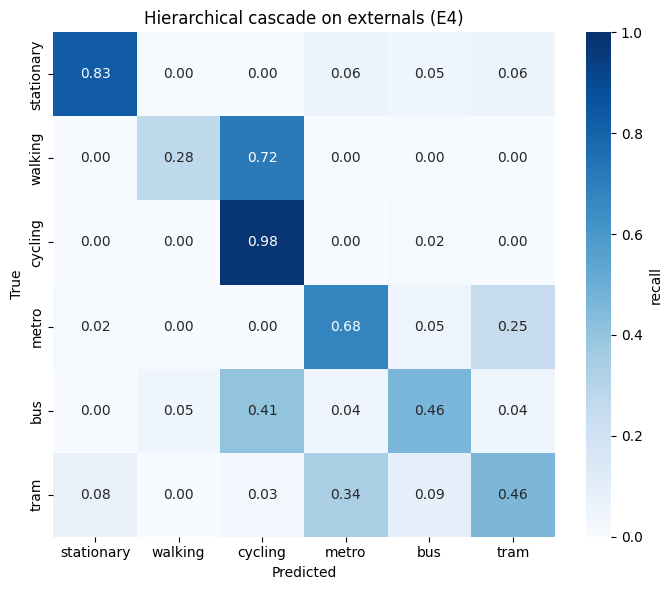

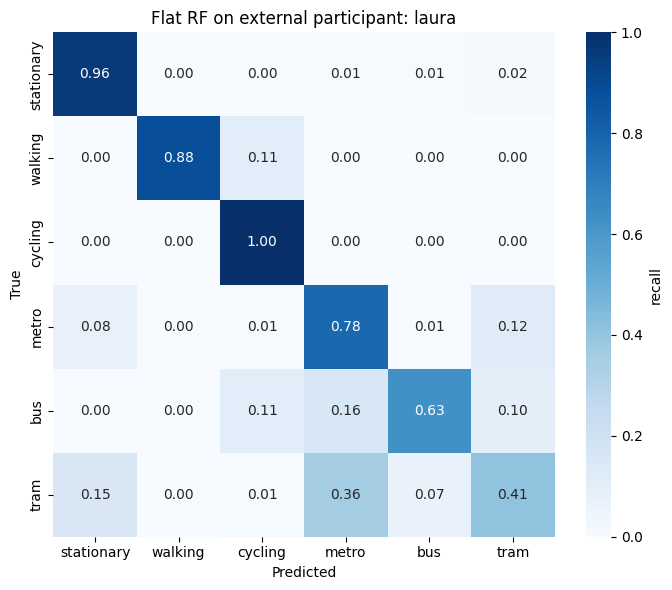

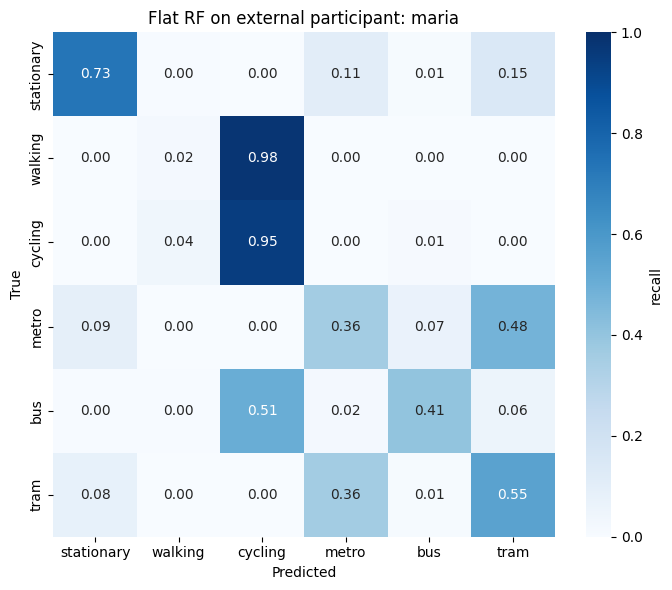

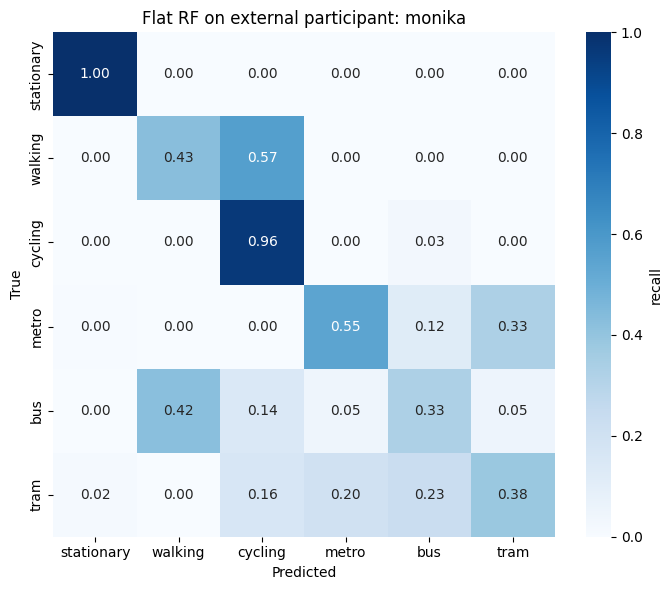

In [13]:
def plot_cm(y_true, y_pred, title, save_path):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(F.MODES))))
    cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(
        cm_norm, annot=True, fmt='.2f', cmap='Blues',
        xticklabels=F.MODES, yticklabels=F.MODES, ax=ax,
        cbar_kws={'label': 'recall'}, vmin=0, vmax=1,
    )
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(title)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

plot_cm(y_ext_true, y_ext_pred_rf,
        'Flat RF + Set A on externals (E4)',
        FIGURES_DIR / 'cm_external_flat_rf.png')

plot_cm(y_ext_true_cascade, y_ext_pred_cascade,
        'Hierarchical cascade on externals (E4)',
        FIGURES_DIR / 'cm_external_cascade.png')

# Per-participant matrices for the flat RF
for p in ext_std['participant'].unique():
    sub = ext_std[ext_std['participant'] == p]
    plot_cm(sub['mode_id'], sub['pred_rf'],
            f'Flat RF on external participant: {p}',
            FIGURES_DIR / f'cm_external_flat_rf_{p}.png')

## 10. Per-class F1: external vs internal

Side-by-side comparison of internal LOSO per-class F1 against external E4 per-class F1. Shows which classes generalize and which break under the wider OOD shift.

In [14]:
# Internal LOSO per-class F1 from notebook 07 (hard-coded)
internal_loso_per_class = {
    'stationary': 0.736, 'walking': 0.721, 'cycling': 0.778,
    'metro': 0.432, 'bus': 0.563, 'tram': 0.394,
}

ext_per_class_rf = f1_score(
    y_ext_true, y_ext_pred_rf,
    labels=list(range(len(F.MODES))), average=None, zero_division=0,
)
ext_per_class_cascade = f1_score(
    y_ext_true_cascade, y_ext_pred_cascade,
    labels=list(range(len(F.MODES))), average=None, zero_division=0,
)

rows = []
for cls_id, mode in enumerate(F.MODES):
    rows.append({
        'mode':                 mode,
        'internal_loso_f1':     internal_loso_per_class[mode],
        'external_e4_flat_rf':  float(ext_per_class_rf[cls_id]),
        'external_e4_cascade':  float(ext_per_class_cascade[cls_id]),
        'delta_flat_rf':        float(ext_per_class_rf[cls_id]) - internal_loso_per_class[mode],
        'delta_cascade':        float(ext_per_class_cascade[cls_id]) - internal_loso_per_class[mode],
    })
per_class_df = pd.DataFrame(rows)
per_class_df.to_csv(RESULTS_DIR / 'external_e4_per_class.csv', index=False)
print('Per-class F1: internal LOSO vs external E4')
print(per_class_df.round(3).to_string(index=False))

Per-class F1: internal LOSO vs external E4
      mode  internal_loso_f1  external_e4_flat_rf  external_e4_cascade  delta_flat_rf  delta_cascade
stationary             0.736                0.884                0.867          0.148          0.131
   walking             0.721                0.498                0.410         -0.223         -0.311
   cycling             0.778                0.672                0.573         -0.106         -0.205
     metro             0.432                0.599                0.686          0.167          0.254
       bus             0.563                0.537                0.579         -0.026          0.016
      tram             0.394                0.422                0.448          0.028          0.054


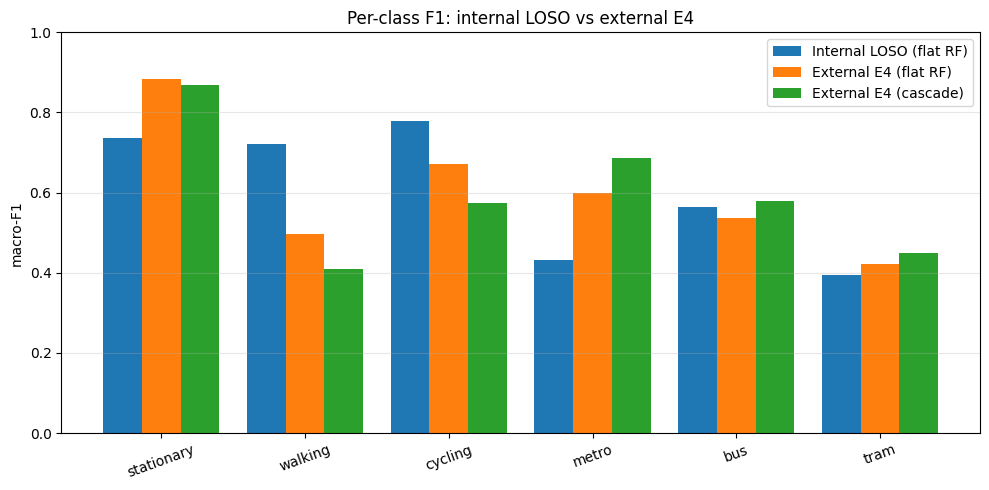

In [15]:
# Bar chart
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(F.MODES))
w = 0.27
ax.bar(x - w, per_class_df['internal_loso_f1'], width=w, label='Internal LOSO (flat RF)')
ax.bar(x,     per_class_df['external_e4_flat_rf'], width=w, label='External E4 (flat RF)')
ax.bar(x + w, per_class_df['external_e4_cascade'], width=w, label='External E4 (cascade)')
ax.set_xticks(x)
ax.set_xticklabels(F.MODES, rotation=20)
ax.set_ylabel('macro-F1')
ax.set_title('Per-class F1: internal LOSO vs external E4')
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'per_class_internal_vs_external.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

## 11. Headline summary

Save the final E4 result table and print the headline numbers for the report.

In [16]:
summary = {
    'flat_rf_e4_macro_f1':      float(rf_e4),
    'cascade_e4_macro_f1':      float(cascade_e4),
    'internal_loso_flat_rf':    INTERNAL_LOSO_FLAT_RF,
    'internal_loso_cascade':    INTERNAL_LOSO_CASCADE,
    'delta_flat_rf':            float(rf_e4 - INTERNAL_LOSO_FLAT_RF),
    'delta_cascade':            float(cascade_e4 - INTERNAL_LOSO_CASCADE),
    'n_external_windows_flat':  int(len(ext_std)),
    'n_external_windows_cas':   int(len(ext_merged)),
    'external_participants':    sorted(ext_std['participant'].unique().tolist()),
}

with open(RESULTS_DIR / 'external_e4_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print('=' * 60)
print('E4 EXTERNAL VALIDATION SUMMARY')
print('=' * 60)
print(f'External participants:     {summary["external_participants"]}')
print(f'External windows:          {summary["n_external_windows_flat"]}')
print()
print(f'Flat RF + Set A:           E4 = {rf_e4:.3f}  '
      f'(internal LOSO {INTERNAL_LOSO_FLAT_RF:.3f}, delta {summary["delta_flat_rf"]:+.3f})')
print(f'Hierarchical cascade:      E4 = {cascade_e4:.3f}  '
      f'(internal LOSO {INTERNAL_LOSO_CASCADE:.3f}, delta {summary["delta_cascade"]:+.3f})')
print('=' * 60)

# Save per-window predictions for later analysis
ext_std[['session_id', 'window_index', 'participant', 'mode', 'mode_id', 'pred_rf']].to_csv(
    RESULTS_DIR / 'external_e4_flat_rf.csv', index=False
)
ext_merged[['session_id', 'window_index', 'participant', 'mode', 'mode_id', 'pred_cascade']].to_csv(
    RESULTS_DIR / 'external_e4_cascade.csv', index=False
)

E4 EXTERNAL VALIDATION SUMMARY
External participants:     ['laura', 'maria', 'monika']
External windows:          5274

Flat RF + Set A:           E4 = 0.602  (internal LOSO 0.568, delta +0.034)
Hierarchical cascade:      E4 = 0.594  (internal LOSO 0.572, delta +0.022)


## 12. Summary and next steps

Artifacts produced:
- `data/interim_external/<session_id>.csv`: preprocessed external sessions.
- `data/processed_external/features_external_*.csv`: four feature CSVs for externals.
- `reports/results/external_e4_summary.json`: headline E4 numbers.
- `reports/results/external_e4_per_class.csv`: per-class F1 comparison.
- `reports/results/external_e4_flat_rf.csv` and `external_e4_cascade.csv`: per-window predictions.
- `reports/figures/cm_external_flat_rf.png`, `cm_external_cascade.png`: confusion matrices.
- `reports/figures/cm_external_flat_rf_<participant>.png`: per-participant matrices.
- `reports/figures/per_class_internal_vs_external.png`: per-class bar chart.

Reading order for the report's external validation section:
1. Headline E4 numbers from section 11 (the two macro-F1 values and their deltas from internal LOSO).
2. Per-class comparison from section 10 (which modes survived OOD).
3. Confusion matrices from section 9 versus the internal ones from notebooks 07 and 08.
4. Per-participant breakdown from sections 7 and 8 (whether Laura or Monika is the harder fold).

If you want to also run the subject-count ablation (idea 2 from the planning conversation: 4-subject and 5-subject LOSO with both RF and TCN), that goes in a separate notebook 10. Ask when ready.